# 02 - Content Strategy Analysis

Five questions a content-strategy team would ask of the catalogue, answered from the processed tables produced by `01_spark_etl.ipynb`:
1. **Growth:** how fast did the catalogue grow, and did the mix of films and series change?
2. **Freshness:** is Netflix adding newer content over time?
3. **Genres:** which genres dominate, and which are growing?
4. **Geography:** how concentrated is production by country?
5. **Audience:** what is the maturity-rating mix?

The same KPIs are then reproduced in SQL (`sql/kpi_queries.sql`, run here on SQLite) to check that the SQL layer used by the dashboard agrees with the pandas analysis.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import json, sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
P = Path('../data/processed'); FIG = Path('../outputs/figures'); MET = Path('../outputs/metrics')
FIG.mkdir(parents=True, exist_ok=True); MET.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
RED, GREY, DARK = '#E50914', '#9E9E9E', '#221F1F'
titles = pd.read_csv(P / 'titles.csv', parse_dates=['date_added'])
genres = pd.read_csv(P / 'title_genres.csv')
kpis = json.load(open(P / 'kpis.json'))
print(json.dumps(kpis, indent=2))

{
  "snapshot_date": "2021-09-25",
  "titles": 8807,
  "movies": 6131,
  "tv_shows": 2676,
  "countries": 104,
  "genres": 64,
  "median_content_age": 4.0,
  "recent_share": 0.6422
}


## 1. Catalogue Growth and Type Mix

type,Movie,TV Show,TV share
year_added,,,
2015,55,26,0.320988
2016,253,176,0.410256
2017,837,349,0.294266
2018,1235,412,0.250152
2019,1423,591,0.293446
2020,1279,594,0.317138
2021,987,504,0.338028


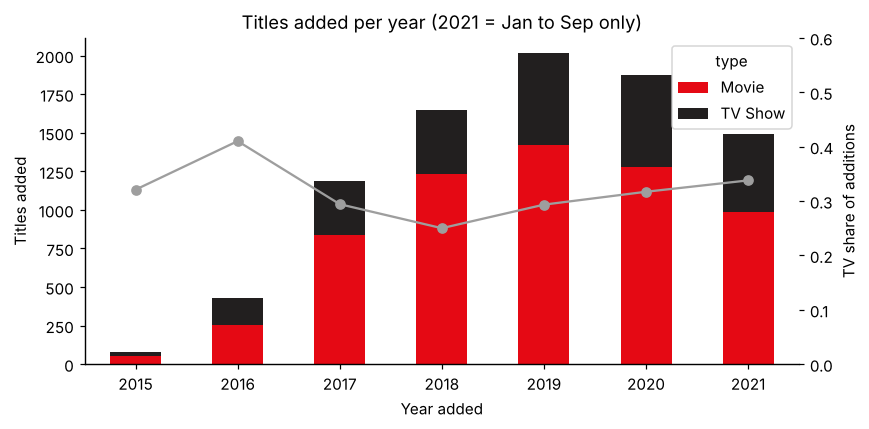

In [2]:
added = titles.dropna(subset=['year_added']).astype({'year_added': int})
by_year = added[added.year_added.between(2015, 2021)].pivot_table(index='year_added', columns='type', values='show_id', aggfunc='count')
by_year['TV share'] = by_year['TV Show'] / by_year.sum(axis=1)
display(by_year)
by_year.to_csv(MET / 'titles_added_by_year.csv')
fig, ax = plt.subplots(figsize=(8, 4))
by_year[['Movie', 'TV Show']].plot.bar(stacked=True, color=[RED, DARK], ax=ax, rot=0)
ax2 = ax.twinx(); ax2.plot(range(len(by_year)), by_year['TV share'], 'o-', color=GREY); ax2.set_ylim(0, 0.6); ax2.set_ylabel('TV share of additions')
ax.set_xlabel('Year added'); ax.set_ylabel('Titles added'); ax.set_title('Titles added per year (2021 = Jan to Sep only)')
plt.tight_layout(); plt.savefig(FIG / 'titles_added_by_year.png', bbox_inches='tight'); plt.show()

**Observation:** Additions grew from 81 titles in 2015 to a peak of 2,014 in 2019, then eased to 1,873 in 2020 (2021 covers only January to September). Movies dominate every year. The TV share of additions dipped to 25% in 2018 and has risen steadily since, to 34% in 2021, so the mix is shifting towards series.

## 2. Freshness

,median_lag_years,share_added_within_1y,share_10y_plus
year_added,,,
2015,0.0,0.815,0.037
2016,1.0,0.655,0.082
2017,1.0,0.598,0.078
2018,1.0,0.548,0.126
2019,1.0,0.516,0.174
2020,1.0,0.555,0.162
2021,1.0,0.508,0.220


,Share of catalogue
content_age_group,
Very recent (0-2y),0.291
Recent (3-5y),0.349
Mature (6-10y),0.184
Older (11-20y),0.110
Legacy (20y+),0.066


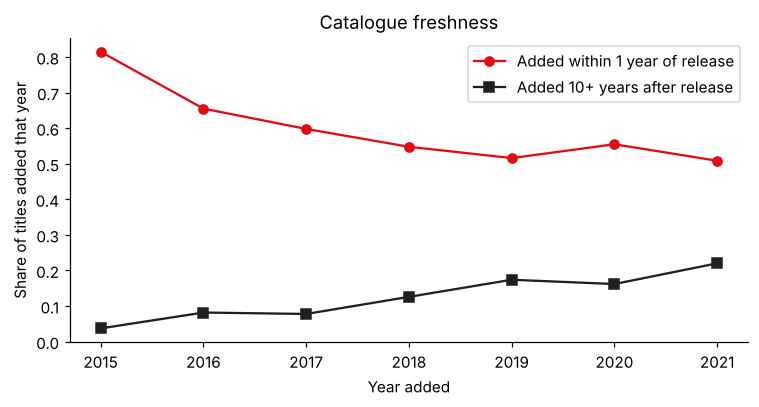

In [3]:
fresh = added[added.year_added.between(2015, 2021)].groupby('year_added').agg(
    median_lag_years=('add_lag_years', 'median'), share_added_within_1y=('is_original_window', 'mean'),
    share_10y_plus=('add_lag_years', lambda s: (s >= 10).mean()))
display(fresh.round(3)); fresh.round(4).to_csv(MET / 'freshness_by_year_added.csv')
age = titles.content_age_group.value_counts(normalize=True).reindex(
    ['Very recent (0-2y)', 'Recent (3-5y)', 'Mature (6-10y)', 'Older (11-20y)', 'Legacy (20y+)']).round(3)
display(age.to_frame('Share of catalogue'))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(fresh.index, fresh.share_added_within_1y, 'o-', color=RED, label='Added within 1 year of release')
ax.plot(fresh.index, fresh.share_10y_plus, 's-', color=DARK, label='Added 10+ years after release')
ax.set_ylabel('Share of titles added that year'); ax.set_xlabel('Year added'); ax.set_title('Catalogue freshness'); ax.legend()
plt.tight_layout(); plt.savefig(FIG / 'freshness.png', bbox_inches='tight'); plt.show()

**Observation:** Netflix is adding *older* content over time. The share of titles added within a year of release fell from 82% in 2015 to 51% in 2021. The share added 10 or more years after release rose from 4% to 22%. The catalogue as a whole is still young (64% is five years old or less at the snapshot), but the growth since 2018 has leaned increasingly on licensed back-catalogue.

## 3. Genres

,Share of titles
genre,
International Movies,0.312
Dramas,0.275
Comedies,0.190
International TV Shows,0.153
Documentaries,0.098
Action & Adventure,0.097
TV Dramas,0.087
Independent Movies,0.085
Children & Family Movies,0.073


,Added 2016-18,Added 2019-21,Share 2016-18,Share 2019-21,Share change (pts)
genre,,,,,
Documentaries,440,403,0.065,0.036,-2.910
International Movies,1145,1589,0.169,0.142,-2.759
Stand-Up Comedy,191,131,0.028,0.012,-1.655
Independent Movies,307,437,0.045,0.039,-0.642
Music & Musicals,162,204,0.024,0.018,-0.576
British TV Shows,110,136,0.016,0.012,-0.413
Romantic TV Shows,146,223,0.022,0.020,-0.170
Sports Movies,85,126,0.013,0.011,-0.133
Docuseries,148,240,0.022,0.021,-0.048


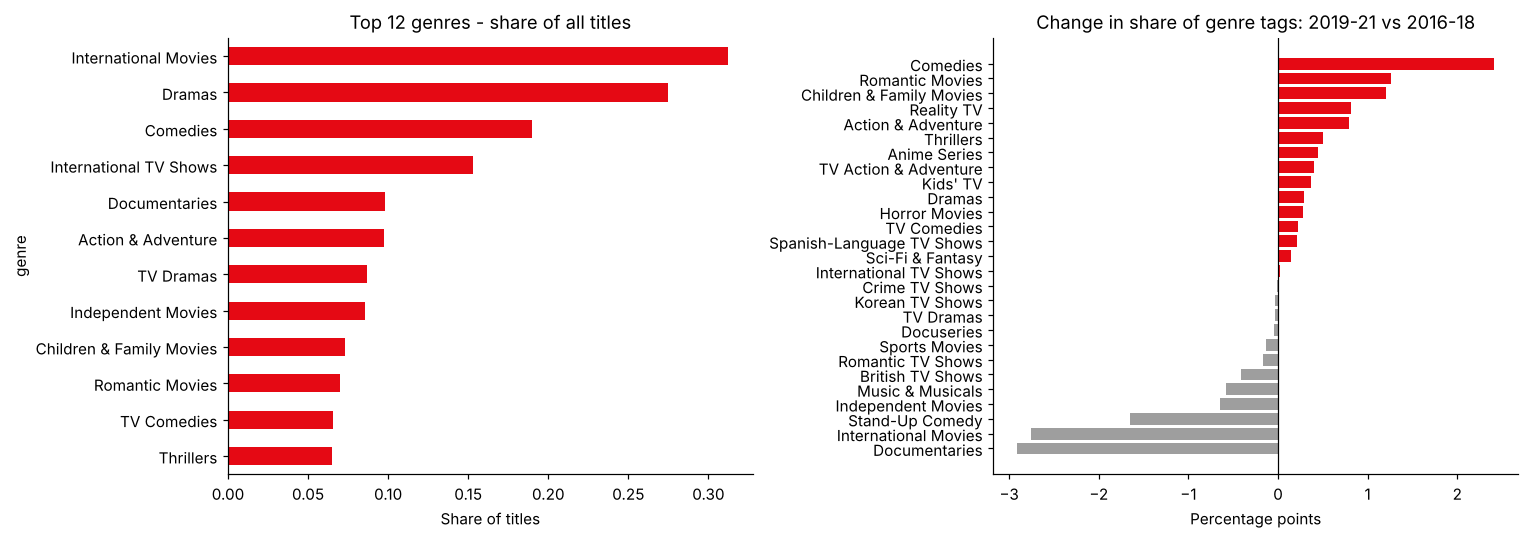

In [4]:
g_counts = genres.groupby('genre').show_id.nunique().sort_values(ascending=False)
g_share = (g_counts / len(titles)).rename('Share of titles')
display(g_share.head(12).round(3).to_frame())
early = genres[genres.year_added.between(2016, 2018)].groupby('genre').show_id.nunique()
late = genres[genres.year_added.between(2019, 2021)].groupby('genre').show_id.nunique()
mom = pd.DataFrame({'Added 2016-18': early, 'Added 2019-21': late}).fillna(0)
mom = mom[mom.sum(axis=1) >= 150]
mom['Share 2016-18'] = mom['Added 2016-18'] / mom['Added 2016-18'].sum(); mom['Share 2019-21'] = mom['Added 2019-21'] / mom['Added 2019-21'].sum()
mom['Share change (pts)'] = 100 * (mom['Share 2019-21'] - mom['Share 2016-18'])
mom = mom.sort_values('Share change (pts)')
display(mom.round(3)); mom.round(4).to_csv(MET / 'genre_momentum.csv')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
g_share.head(12)[::-1].plot.barh(ax=axes[0], color=RED); axes[0].set_title('Top 12 genres - share of all titles'); axes[0].set_xlabel('Share of titles')
axes[1].barh(mom.index, mom['Share change (pts)'], color=[RED if v > 0 else GREY for v in mom['Share change (pts)']])
axes[1].axvline(0, color='black', lw=0.8); axes[1].set_title('Change in share of genre tags: 2019-21 vs 2016-18'); axes[1].set_xlabel('Percentage points')
plt.tight_layout(); plt.savefig(FIG / 'genres.png', bbox_inches='tight'); plt.show()

**Observation:** International Movies (31% of titles), Dramas (28%) and Comedies (19%) lead the catalogue. Comparing the share of genre tags added in 2019-21 with 2016-18, **Comedies (+2.4 pts), Romantic Movies (+1.3) and Children & Family Movies (+1.2) gained** most, while **Documentaries (-2.9), International Movies (-2.8) and Stand-Up Comedy (-1.7) lost** share. International Movies still grew in absolute numbers (1,145 to 1,589) but more slowly than the catalogue overall.

## 4. Geography

,Share of titles with known country
primary_country,
United States,0.401
India,0.126
United Kingdom,0.079
Canada,0.034
Japan,0.032
France,0.026
South Korea,0.026
Spain,0.022
Mexico,0.017


Top 2 countries: 52.7% | top 10: 77.9% | countries: 104
Titles with no country recorded: 9.4%


,US share,India share
year_added,,
2015,0.679,0.000
2016,0.437,0.027
2017,0.359,0.136
2018,0.327,0.222
2019,0.413,0.114
2020,0.401,0.109
2021,0.473,0.088


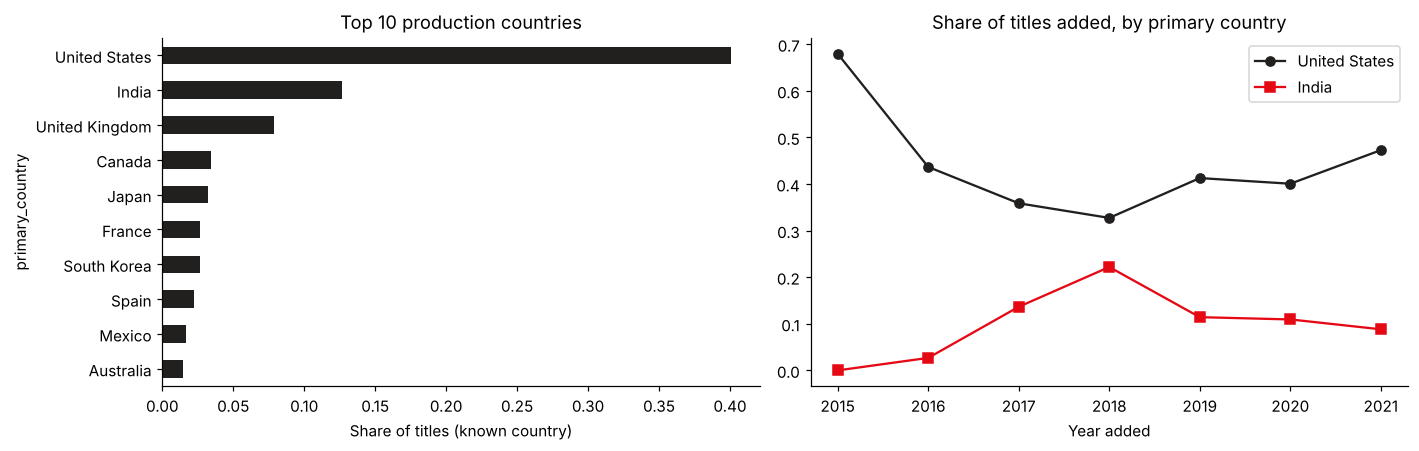

In [5]:
known = titles[titles.primary_country != 'Unknown']
c_share = known.primary_country.value_counts(normalize=True)
display(c_share.head(10).round(3).to_frame('Share of titles with known country'))
print(f"Top 2 countries: {c_share.iloc[:2].sum():.1%} | top 10: {c_share.iloc[:10].sum():.1%} | countries: {known.primary_country.nunique()}")
print(f"Titles with no country recorded: {(titles.primary_country == 'Unknown').mean():.1%}")
us_share = (added[added.year_added.between(2015, 2021) & (added.primary_country != 'Unknown')]
            .assign(us=lambda d: d.primary_country == 'United States').groupby('year_added').us.mean())
in_share = (added[added.year_added.between(2015, 2021) & (added.primary_country != 'Unknown')]
            .assign(ind=lambda d: d.primary_country == 'India').groupby('year_added').ind.mean())
geo = pd.DataFrame({'US share': us_share, 'India share': in_share}); display(geo.round(3)); geo.round(4).to_csv(MET / 'country_share_by_year.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
c_share.head(10)[::-1].plot.barh(ax=axes[0], color=DARK); axes[0].set_title('Top 10 production countries'); axes[0].set_xlabel('Share of titles (known country)')
axes[1].plot(geo.index, geo['US share'], 'o-', color=DARK, label='United States'); axes[1].plot(geo.index, geo['India share'], 's-', color=RED, label='India')
axes[1].set_title('Share of titles added, by primary country'); axes[1].set_xlabel('Year added'); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / 'geography.png', bbox_inches='tight'); plt.show()

**Observation:** Production is concentrated. The US (40%) and India (13%) together account for 53% of titles with a known country, and the top 10 countries account for 78%. India's share of additions rose from 0% in 2015 to a peak of 22% in 2018, then fell back to 9% by 2021, while the US share recovered from 33% to 47%. The 2017-18 international push did not continue. 9.4% of titles have no country recorded.

## 5. Audience Mix

In [6]:
aud = pd.crosstab(titles.type, titles.audience, normalize='index').reindex(columns=['Kids & family', 'Teens', 'Adults', 'Unrated'])
display(aud.round(3)); aud.round(4).to_csv(MET / 'audience_mix_by_type.csv')
print('Most common rating:', titles.rating.mode()[0], f"({(titles.rating == titles.rating.mode()[0]).mean():.1%} of titles)")

audience,Kids & family,Teens,Adults,Unrated
type,,,,
Movie,0.207,0.312,0.465,0.016
TV Show,0.295,0.274,0.428,0.004


Most common rating: TV-MA (36.3% of titles)


**Observation:** Netflix skews adult. TV-MA is the most common rating (36% of titles), and adults are the largest audience group for both movies (47%) and TV shows (43%). TV shows have a noticeably larger kids-and-family share than movies (30% vs 21%).

## 6. SQL Cross-Check
The KPI queries the dashboard relies on (`sql/kpi_queries.sql`) are run against an in-memory SQLite copy of the processed tables and compared with pandas.

In [7]:
con = sqlite3.connect(':memory:')
titles.assign(date_added=titles.date_added.dt.strftime('%Y-%m-%d')).to_sql('titles', con, index=False)
genres.to_sql('title_genres', con, index=False)
sql_text = Path('../sql/kpi_queries.sql').read_text()
queries = {}
for block in sql_text.split('-- name: ')[1:]:
    name, q = block.split('\n', 1); queries[name.strip()] = q.strip().rstrip(';')
results = {k: pd.read_sql(q, con) for k, q in queries.items()}
for k, v in results.items(): print(f'--- {k}'); display(v.head(8))
checks = {
    'total titles': int(results['kpi_summary'].total_titles[0]) == len(titles),
    'movies': int(results['kpi_summary'].movies[0]) == (titles.type == 'Movie').sum(),
    'top genre matches pandas': results['top_genres'].genre[0] == g_counts.index[0],
    'top genre count matches pandas': int(results['top_genres'].title_count[0]) == int(g_counts.iloc[0]),
    'naive COUNT(*) inflates genre-joined totals': int(results['grain_trap'].naive_rows[0]) > int(results['grain_trap'].distinct_titles[0]),
}
for k, v in checks.items(): print(('PASS ' if v else 'FAIL ') + k)
assert all(checks.values())

--- kpi_summary


,total_titles,movies,tv_shows,avg_content_age,recent_share,countries
0,8807,6131,2676,6.8,0.642,104


--- titles_added_by_year


,year_added,type,title_count
0,2015.0,Movie,55
1,2015.0,TV Show,26
2,2016.0,Movie,253
3,2016.0,TV Show,176
4,2017.0,Movie,837
5,2017.0,TV Show,349
6,2018.0,Movie,1235
7,2018.0,TV Show,412


--- freshness_by_year


,year_added,share_added_within_1y,share_10y_plus
0,2015.0,0.815,0.037
1,2016.0,0.655,0.082
2,2017.0,0.598,0.078
3,2018.0,0.548,0.126
4,2019.0,0.516,0.174
5,2020.0,0.555,0.162
6,2021.0,0.508,0.220


... (5 outputs left out)

,type,audience,title_count
0,Movie,Adults,2849
1,Movie,Teens,1915
2,Movie,Kids & family,1267
3,Movie,Unrated,100
4,TV Show,Adults,1145
5,TV Show,Kids & family,789
6,TV Show,Teens,732
7,TV Show,Unrated,10


--- grain_trap


,naive_rows,distinct_titles
0,19303,8806


PASS total titles
PASS movies
PASS top genre matches pandas
PASS top genre count matches pandas
PASS naive COUNT(*) inflates genre-joined totals


**Observation:** All SQL KPIs match the pandas results exactly (total titles, movies, top genre and its count). The `grain_trap` query shows why grain matters: joining titles to genres returns 19,303 rows for 8,806 titles with at least one genre. A naive `COUNT(*)` on the joined table would more than double every title KPI. The dashboard and SQL layer use `COUNT(DISTINCT show_id)` for title-level metrics.

# Findings

| Question | Finding |
|---|---|
| Growth | Additions peaked at 2,014 titles in 2019. The TV share of additions has risen from 25% (2018) to 34% (2021). |
| Freshness | Same-year additions fell from 82% (2015) to 51% (2021). Additions of 10+-year-old titles rose from 4% to 22%: growth increasingly relies on back-catalogue. |
| Genres | Comedies, romance and family titles gained share in 2019-21. Documentaries, international movies and stand-up lost share. |
| Geography | US + India = 53% of titles. India's surge peaked in 2018 (22% of additions) and fell back to 9%. |
| Audience | Adult-skewed: TV-MA is 36% of the catalogue. |
| Data engineering | Snapshot anchoring changes the 'recent' share from 6.7% to 64.2%. Genre explosion inflates naive counts by 2.2x. |

**Limitations:** The dataset is a public snapshot of the catalogue up to September 2021. It has no viewing, revenue or regional-availability data, so it describes what Netflix *added*, not what members *watched*. Removed titles are not included, and 2021 covers only nine months.